In [1]:
import re
import time
from pathlib import Path
from urllib.parse import urljoin

import pandas as pd
import requests
from bs4 import BeautifulSoup
from IPython.display import display, Image

# Часть 1. Парсинг сайта с помощью BeautifulSoup

Cайт: https://books.toscrape.com/catalogue/category/books/mystery_3/index.html

Получим сведения о книгах.

In [2]:
START_URL = "https://books.toscrape.com/catalogue/category/books/mystery_3/index.html"
MAX_PAGES = 2
TIMEOUT = 20
RETRIES = 2

print(f"Стартовая страница: {START_URL}")
print(f"Количество страниц: {MAX_PAGES}")

Стартовая страница: https://books.toscrape.com/catalogue/category/books/mystery_3/index.html
Количество страниц: 2


### 1.1. Получение HTML

Используем `requests.get()` с `timeout=20`. При ошибке делаем до двух повторных попыток.

In [3]:
def fetch_html(url):
    for attempt in range(RETRIES + 1):
        try:
            response = requests.get(
                url,
                headers={"User-Agent": "Mozilla/5.0 (Educational scraping practice)"},
                timeout=TIMEOUT,
            )
            response.raise_for_status()
            return response.content
        except requests.RequestException as error:
            if attempt == RETRIES:
                raise RuntimeError(f"Не удалось получить {url}") from error

            delay = 2 ** attempt
            print(f"Ошибка запроса: {error}. Повтор через {delay} сек.")
            time.sleep(delay)

### 1.2. Извлечение данных

CSS-селекторы:
- article.product_pod - карточка книги;
- h3 a - название (title) и ссылка (href);
- ul.breadcrumb li.active - категория книг Mystery;
- p.price_color - цена;
- p.star-rating - рейтинг в CSS-классе;
- p.instock.availability - наличие;
- li.next a - переход на следующую страницу.

Идентификатор из data-* извлекается при наличии атрибута.

In [4]:
RATING_MAP = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}


def clean_text(value):
    return re.sub(r"\s+", " ", str(value or "")).strip()


def parse_page(html, page_url):
    soup = BeautifulSoup(html, "html.parser")
    category_tag = soup.select_one("ul.breadcrumb li.active")
    category = clean_text(category_tag.get_text(" ", strip=True)) if category_tag else None
    records = []

    for card in soup.select("article.product_pod"):
        title_tag = card.select_one("h3 a")
        price_tag = card.select_one("p.price_color")
        rating_tag = card.select_one("p.star-rating")
        stock_tag = card.select_one("p.instock.availability")

        title = clean_text(title_tag.get("title") or title_tag.get_text(" ", strip=True)) if title_tag else None
        href = title_tag.get("href") if title_tag else None
        link = urljoin(page_url, href) if href else None

        price_text = clean_text(price_tag.get_text(" ", strip=True)) if price_tag else ""
        match = re.search(r"\d+(?:[.,]\d+)?", price_text)
        price = float(match.group(0).replace(",", ".")) if match else None

        rating_classes = rating_tag.get("class", []) if rating_tag else []
        rating = next((RATING_MAP[c] for c in rating_classes if c in RATING_MAP), None)
        availability = clean_text(stock_tag.get_text(" ", strip=True)) if stock_tag else None

        identifier = None
        for element in [card] + card.find_all(True):
            attrs = [(key, value) for key, value in element.attrs.items()
                     if key.startswith("data-") and "id" in key]
            if attrs:
                identifier = clean_text(attrs[0][1])
                break

        records.append({
            "title": title,
            "category": category,
            "price_gbp": price,
            "rating": rating,
            "availability": availability,
            "url": link,
            "identifier": identifier,
        })

    next_tag = soup.select_one("li.next a")
    next_url = urljoin(page_url, next_tag.get("href")) if next_tag else None
    return records, next_url

### 1.3. Парсинг двух страниц

In [5]:
raw_records = []
current_url = START_URL

for page_num in range(1, MAX_PAGES + 1):
    if not current_url:
        break

    html = fetch_html(current_url)
    page_records, next_url = parse_page(html, current_url)
    if not page_records:
        raise ValueError(f"Не найдены карточки книг: {current_url}")

    raw_records.extend(page_records)
    print(f"Страница {page_num}: {len(page_records)} записей | {current_url}")
    current_url = next_url

    if page_num < MAX_PAGES and current_url:
        time.sleep(0.5)

print(f"Всего извлечено: {len(raw_records)} записей")

Страница 1: 20 записей | https://books.toscrape.com/catalogue/category/books/mystery_3/index.html
Страница 2: 12 записей | https://books.toscrape.com/catalogue/category/books/mystery_3/page-2.html
Всего извлечено: 32 записей


### 1.4. Очистка данных

Убираем лишние пробелы, приводим цену и рейтинг к числовому типу, удаляем дубликаты по ссылке. Если атрибутов data-* с идентификатором нет, пустой столбец не сохраняем.

In [6]:
books_df = pd.DataFrame(raw_records)

for column in ["title", "category", "availability", "url", "identifier"]:
    books_df[column] = books_df[column].apply(
        lambda value: clean_text(value) if pd.notna(value) else None
    )

books_df["price_gbp"] = pd.to_numeric(books_df["price_gbp"], errors="coerce")
books_df["rating"] = pd.to_numeric(books_df["rating"], errors="coerce").astype("Int64")
books_df = books_df.replace(r"^\s*$", pd.NA, regex=True)

before = len(books_df)
books_df = books_df.drop_duplicates(subset=["url"]).reset_index(drop=True)

if books_df["identifier"].isna().all():
    books_df = books_df.drop(columns=["identifier"])
    print("Атрибут data-* с идентификатором не найден; поле необязательное.")

print(f"Удалено дубликатов: {before - len(books_df)}")
print(f"Осталось записей: {len(books_df)}")

Атрибут data-* с идентификатором не найден; поле необязательное.
Удалено дубликатов: 0
Осталось записей: 32


### 1.5. Результаты и проверка требований

In [7]:
print(f"Количество строк: {len(books_df)}")
print(f"Общая доля пропусков: {books_df.isna().to_numpy().mean():.2%}")
print("Доля пропусков по столбцам:")
print((books_df.isna().mean() * 100).round(2).astype(str) + "%")

print("\nПервые пять записей:")
display(books_df.head(5))

assert len(books_df) >= 20, "Должно быть не менее 20 записей"
assert pd.api.types.is_numeric_dtype(books_df["price_gbp"])
assert pd.api.types.is_numeric_dtype(books_df["rating"])
print("\nПроверки пройдены.")

Количество строк: 32
Общая доля пропусков: 0.00%
Доля пропусков по столбцам:
title           0.0%
category        0.0%
price_gbp       0.0%
rating          0.0%
availability    0.0%
url             0.0%
dtype: str

Первые пять записей:


,title,category,price_gbp,rating,availability,url
0,Sharp Objects,Mystery,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
1,"In a Dark, Dark Wood",Mystery,19.63,1,In stock,https://books.toscrape.com/catalogue/in-a-dark...
2,The Past Never Ends,Mystery,56.50,4,In stock,https://books.toscrape.com/catalogue/the-past-...
3,A Murder in Time,Mystery,16.64,1,In stock,https://books.toscrape.com/catalogue/a-murder-...
4,The Murder of Roger Ackroyd (Hercule Poirot #4),Mystery,44.10,4,In stock,https://books.toscrape.com/catalogue/the-murde...



Проверки пройдены.


### 1.6. Сохранение и скачивание CSV

In [8]:
python_csv = "books_beautifulsoup.csv"
books_df.to_csv(python_csv, index=False, encoding="utf-8-sig")

check_df = pd.read_csv(python_csv, encoding="utf-8-sig")
print(f"Файл сохранён: {python_csv}")
print(f"Прочитано из файла: {len(check_df)} строк")

Файл сохранён: books_beautifulsoup.csv
Прочитано из файла: 32 строк


In [9]:
try:
    from google.colab import files
    files.download(python_csv)
except ImportError:
    print(f"Файл находится в текущей папке: {python_csv}")

Файл находится в текущей папке: books_beautifulsoup.csv


# Часть 2. Парсинг в Octoparse

В Octoparse создана задача Mystery | Books to Scrape - Sandbox для той же категории книг. Выполнен локальный запуск:*32 записи, 0 дубликатов, 18 секунд. Результат выгружен в `octoparse_export.csv`.

1. **Go to Webpage** открывает `https://books.toscrape.com/catalogue/category/books/mystery_3/index.html`.
2. **Pagination** повторяет обработку страниц каталога.
3. **Loop Item** перебирает карточки книг (article.product_pod).
4. **Extract Data** извлекает четыре поля из каждой карточки.
5. **Click to Paginate** нажимает кнопку next (li.next a). На второй странице кнопки нет, и сбор заканчивается.

Запуск: Run → Run on your device → Auto → Run Now. После завершения выбран Export → CSV → Confirm. Получены 20 книг с первой страницы и 12 со второй.

### 2.1. Сравнение программного и no-code результатов

Сравниваем количество строк, набор полей и значения общих полей по ссылке книги. В исходном экспорте Octoparse цена содержит `£`, а наличие - пробелы и переносы строк. Перед сравнением очищаем их в памяти. Сам файл экспорта сохраняется без изменений.

In [10]:
octoparse_raw = pd.read_csv("octoparse_export.csv", encoding="utf-8-sig", dtype=str)
octoparse_df = octoparse_raw.copy()
octoparse_df.columns = [clean_text(c) for c in octoparse_df.columns]
required_fields = ["title", "url", "price_gbp", "availability"]
assert set(required_fields).issubset(octoparse_df.columns), "Не хватает полей Octoparse"

for column in required_fields:
    octoparse_df[column] = octoparse_df[column].map(
        lambda value: clean_text(value) if pd.notna(value) else pd.NA
    )
octoparse_df = octoparse_df.replace(r"^\s*$", pd.NA, regex=True)
octoparse_df["price_gbp"] = pd.to_numeric(
    octoparse_df["price_gbp"].str.replace("£", "", regex=False), errors="raise"
)

common_fields = sorted(set(books_df.columns) & set(octoparse_df.columns))
print("BeautifulSoup:", len(books_df), "записей")
print("Octoparse:", len(octoparse_df), "записей")
print("Поля BeautifulSoup:", list(books_df.columns))
print("Поля Octoparse:", list(octoparse_df.columns))
print("Общие поля:", common_fields)
print("Дополнительно в Python:", sorted(set(books_df.columns) - set(octoparse_df.columns)))
print("Доля пропусков Octoparse:", f"{octoparse_df.isna().to_numpy().mean():.2%}")
print("Повторяющихся ссылок Octoparse:", int(octoparse_df["url"].duplicated().sum()))

assert not octoparse_df["url"].duplicated().any()
assert not octoparse_df[required_fields].isna().any().any()
assert len(books_df) == len(octoparse_df)
assert set(books_df["url"]) == set(octoparse_df["url"])

left = books_df.set_index("url").sort_index()
right = octoparse_df.set_index("url").reindex(left.index)
comparison_rows = [{"field": "url", "matched": len(left), "different": 0}]
for column in ["title", "price_gbp", "availability"]:
    equal = left[column].eq(right[column])
    comparison_rows.append({
        "field": column, "matched": int(equal.sum()), "different": int((~equal).sum())
    })
comparison = pd.DataFrame(comparison_rows)
print("\nСравнение значений общих полей:")
display(comparison)
assert comparison["different"].sum() == 0, "Обнаружены отличия между результатами"

print("\nПервые пять записей Octoparse после очистки для сравнения:")
display(octoparse_df.head(5))
print("Все общие поля совпали для всех книг.")

BeautifulSoup: 32 записей
Octoparse: 32 записей
Поля BeautifulSoup: ['title', 'category', 'price_gbp', 'rating', 'availability', 'url']
Поля Octoparse: ['title', 'url', 'price_gbp', 'availability']
Общие поля: ['availability', 'price_gbp', 'title', 'url']
Дополнительно в Python: ['category', 'rating']
Доля пропусков Octoparse: 0.00%
Повторяющихся ссылок Octoparse: 0

Сравнение значений общих полей:


,field,matched,different
0,url,32,0
1,title,32,0
2,price_gbp,32,0
3,availability,32,0



Первые пять записей Octoparse после очистки для сравнения:


,title,url,price_gbp,availability
0,Sharp Objects,https://books.toscrape.com/catalogue/sharp-obj...,47.82,In stock
1,"In a Dark, Dark Wood",https://books.toscrape.com/catalogue/in-a-dark...,19.63,In stock
2,The Past Never Ends,https://books.toscrape.com/catalogue/the-past-...,56.50,In stock
3,A Murder in Time,https://books.toscrape.com/catalogue/a-murder-...,16.64,In stock
4,The Murder of Roger Ackroyd (Hercule Poirot #4),https://books.toscrape.com/catalogue/the-murde...,44.10,In stock


Все общие поля совпали для всех книг.


### 2.2. Скриншоты workflow и таблицы

Первый снимок показывает схему с циклами страниц и карточек, а также четыре выбранных поля. Нижняя таблица в редакторе - предварительный просмотр первой страницы. Второй снимок сделан после выполнения: всего 32 записи, статус Completed.

octoparse_workflow.png


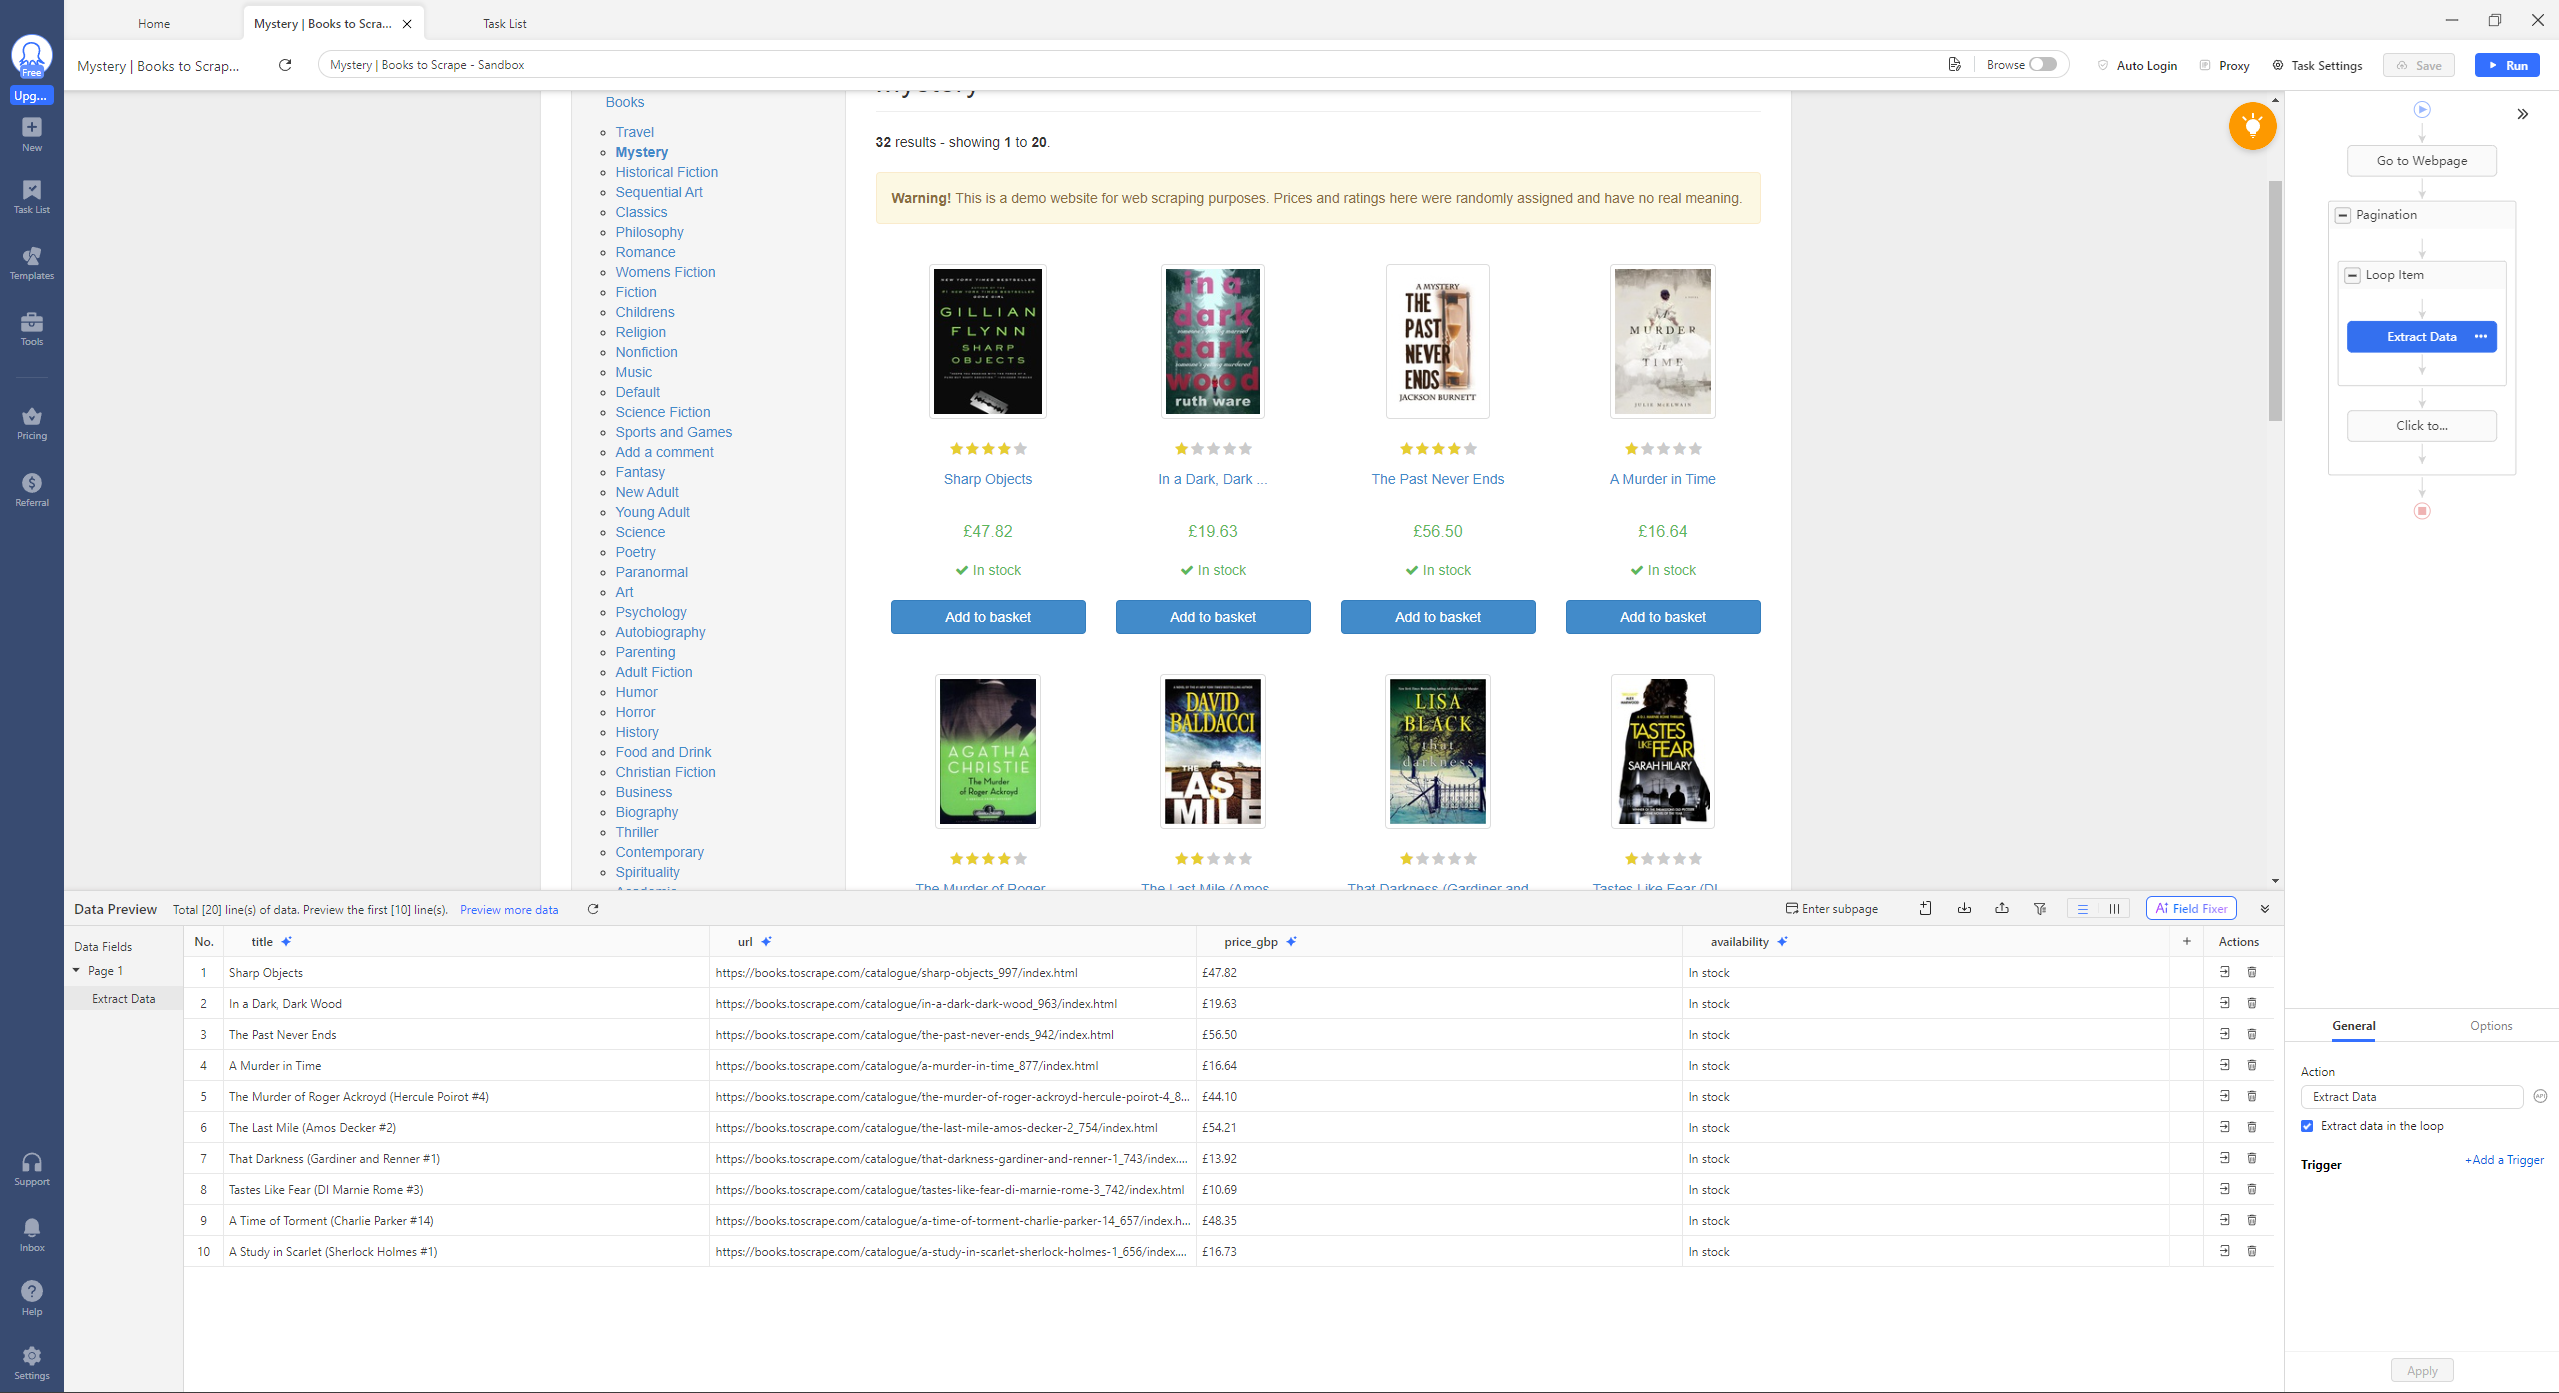

octoparse_table.png


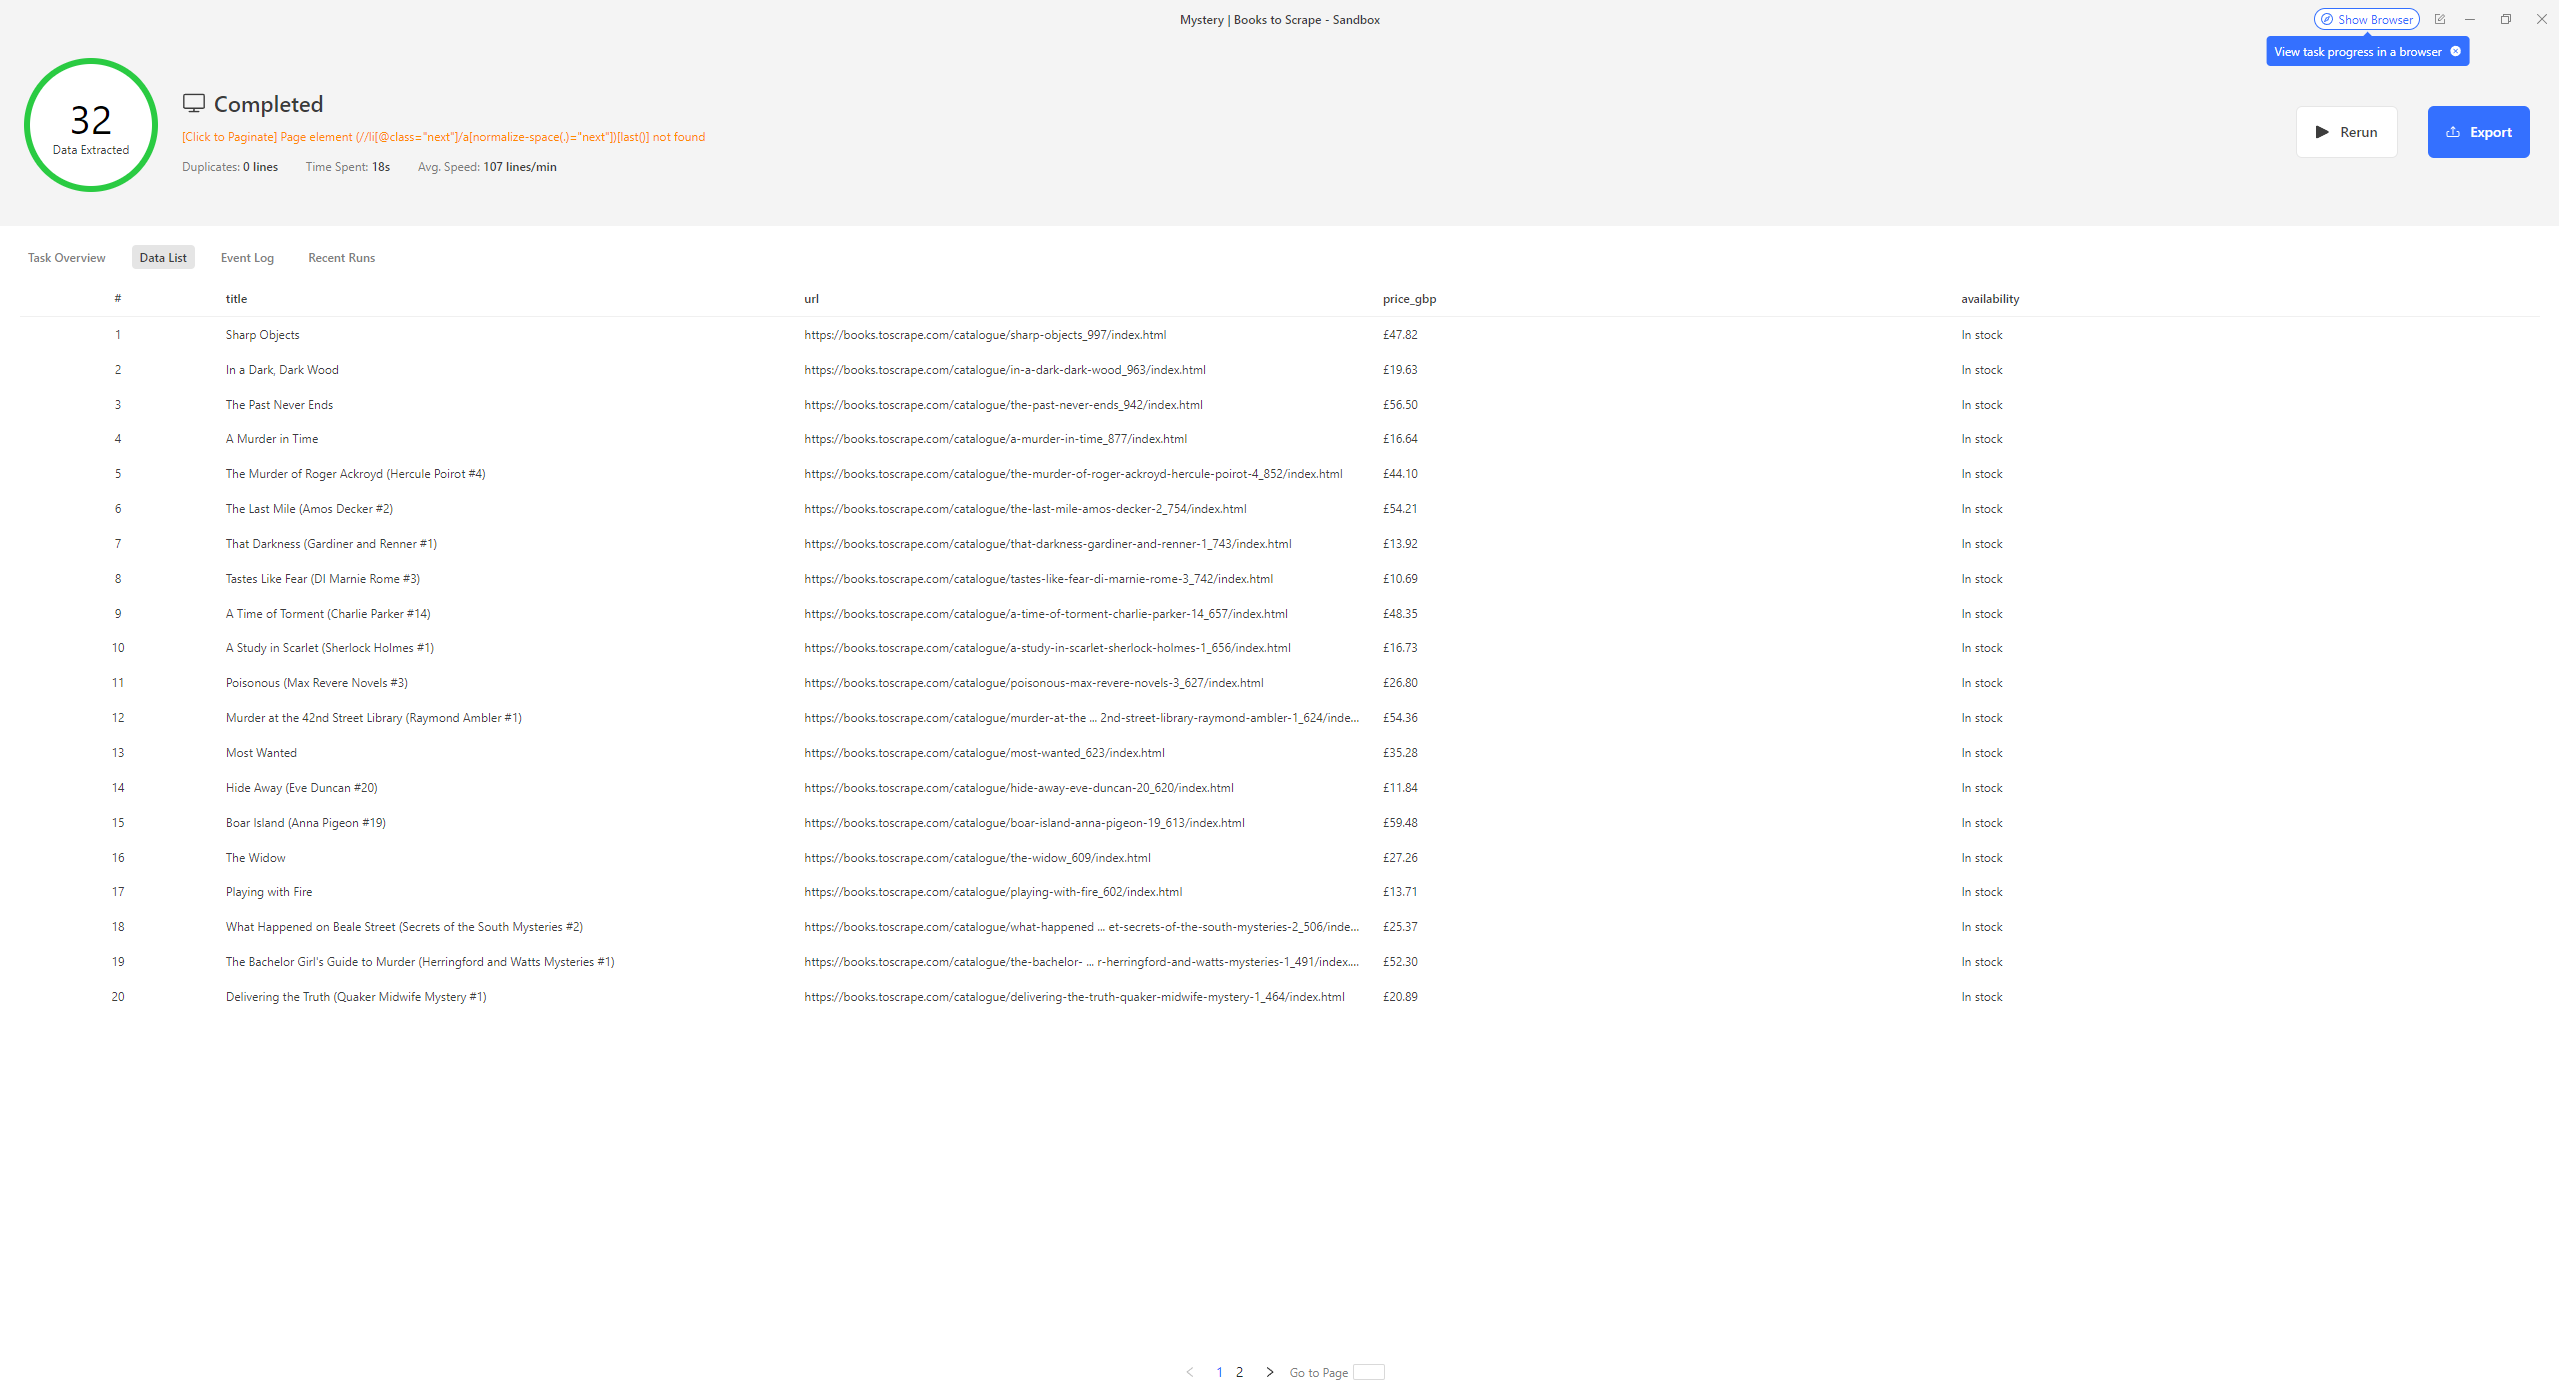

In [11]:
for screenshot in ["octoparse_workflow.png", "octoparse_table.png"]:
    print(screenshot)
    display(Image(filename=screenshot, width=1200))

# Итоговый вывод

Данные со статического учебного сайта Books to Scrape собраны двумя способами: на Python с BeautifulSoup и в Octoparse. В обоих случаях обработаны две страницы категории Mystery и получены 32 книги без повторяющихся ссылок и пропусков.

В Python сохранены шесть полей: название, категория, цена, рейтинг, наличие и ссылка. В Octoparse сохранены четыре поля: название, ссылка, цена и наличие. После удаления знака валюты и лишних пробелов все общие поля совпали.

Python позволяет явно задать очистку и проверки данных. В Octoparse последовательность сбора можно настроить визуально: открыть страницу, пройти карточки, извлечь поля и перейти на следующую страницу.